In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt

In [2]:
env = gym.make("CartPole-v1",render_mode="rgb_array")
obs = env.reset()

In [3]:
obs

(array([-0.01056072, -0.01031805,  0.0060257 ,  0.04470326], dtype=float32),
 {})

In [4]:
print(list(gym.envs.registry.keys()))

['CartPole-v0', 'CartPole-v1', 'MountainCar-v0', 'MountainCarContinuous-v0', 'Pendulum-v1', 'Acrobot-v1', 'phys2d/CartPole-v0', 'phys2d/CartPole-v1', 'phys2d/Pendulum-v0', 'LunarLander-v3', 'LunarLanderContinuous-v3', 'BipedalWalker-v3', 'BipedalWalkerHardcore-v3', 'CarRacing-v3', 'Blackjack-v1', 'FrozenLake-v1', 'FrozenLake8x8-v1', 'CliffWalking-v1', 'CliffWalkingSlippery-v1', 'Taxi-v3', 'tabular/Blackjack-v0', 'tabular/CliffWalking-v0', 'Reacher-v2', 'Reacher-v4', 'Reacher-v5', 'Pusher-v2', 'Pusher-v4', 'Pusher-v5', 'InvertedPendulum-v2', 'InvertedPendulum-v4', 'InvertedPendulum-v5', 'InvertedDoublePendulum-v2', 'InvertedDoublePendulum-v4', 'InvertedDoublePendulum-v5', 'HalfCheetah-v2', 'HalfCheetah-v3', 'HalfCheetah-v4', 'HalfCheetah-v5', 'Hopper-v2', 'Hopper-v3', 'Hopper-v4', 'Hopper-v5', 'Swimmer-v2', 'Swimmer-v3', 'Swimmer-v4', 'Swimmer-v5', 'Walker2d-v2', 'Walker2d-v3', 'Walker2d-v4', 'Walker2d-v5', 'Ant-v2', 'Ant-v3', 'Ant-v4', 'Ant-v5', 'Humanoid-v2', 'Humanoid-v3', 'Humanoid-

C:\Users\Berkay\Desktop\ML_projects\LSTM_sentiment\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


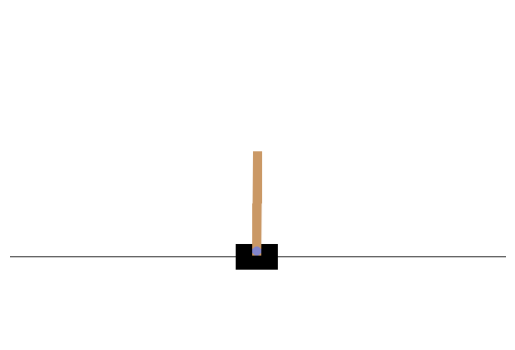

In [5]:
img = env.render()
plt.imshow(img)
plt.axis("off")
plt.show()

In [6]:
env.action_space #actions available

Discrete(2)

In [7]:
action = 1 #go right
obs, reward, terminated, truncated, info = env.step(action)
done = terminated or truncated
obs

array([-0.01076708,  0.18471698,  0.00691977, -0.24607243], dtype=float32)

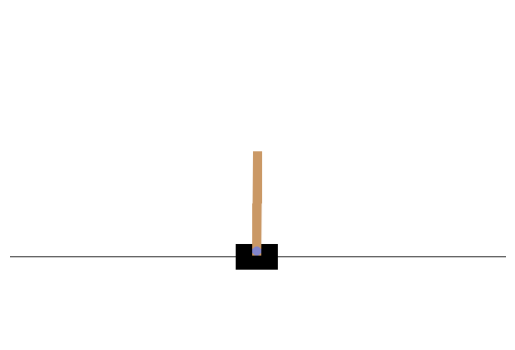

In [8]:
img = env.render()
plt.imshow(img)
plt.axis("off")
plt.show()

In [9]:
reward

1.0

In [10]:
done

False

In [11]:
info

{}

In [12]:
def basic_policy(obs):
    angle = obs[2]
    return 0 if angle < 0 else 1

In [13]:
totals = []
for episode in range(500):
    episode_rewards = 0
    obs, info = env.reset()
    for step in range(200):
        action = basic_policy(obs)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        episode_rewards += reward
        if done:
            break
        totals.append(episode_rewards) 

In [14]:
import numpy as np

np.mean(totals), np.std(totals), np.min(totals), np.max(totals)

(np.float64(22.270731473492475),
 np.float64(13.5356148993875),
 np.float64(1.0),
 np.float64(67.0))

In [15]:
import tensorflow as tf
from tensorflow import keras

n_inputs = 4 #amount of obs available

model = keras.models.Sequential([
    keras.layers.Dense(5, activation="elu", input_shape=[n_inputs]),
    keras.layers.Dense(1, activation="sigmoid"),
])

C:\Users\Berkay\Desktop\ML_projects\LSTM_sentiment\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
